# K-Nearest Neighbors (KNN) — Iris Classification

This project implements the K-Nearest Neighbors algorithm from scratch and evaluates it on the Iris dataset using three distance measures:

- Euclidean distance
- Manhattan distance
- Cosine distance (1 − cosine similarity)

The notebook compares the performance of these distance measures on a held-out test set.

## 1. Import libraries

Scikit-learn is used to load the built-in Iris dataset, split the data, scale features, and calculate evaluation metrics. The KNN algorithm and its distance calculations are implemented manually.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from math import sqrt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

## 2. Load and explore the Iris dataset

The original notebook loaded `Iris.csv` from a fixed Google Colab path and included all columns except `Species`. Some versions of this dataset contain an `Id` column; an identifier is not a meaningful measurement, so this version uses only the four flower measurements.

The built-in scikit-learn dataset makes the notebook reproducible without a separate CSV upload.

In [ ]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["Species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns=["target"])

print("First five rows:")
display(df.head())

print("\\nDataset information:")
print(df.info())

print("\\nMissing values:")
display(df.isnull().sum())

print("\\nSummary statistics:")
display(df.describe())

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
\nMissing values:


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
Species,0


\nSummary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


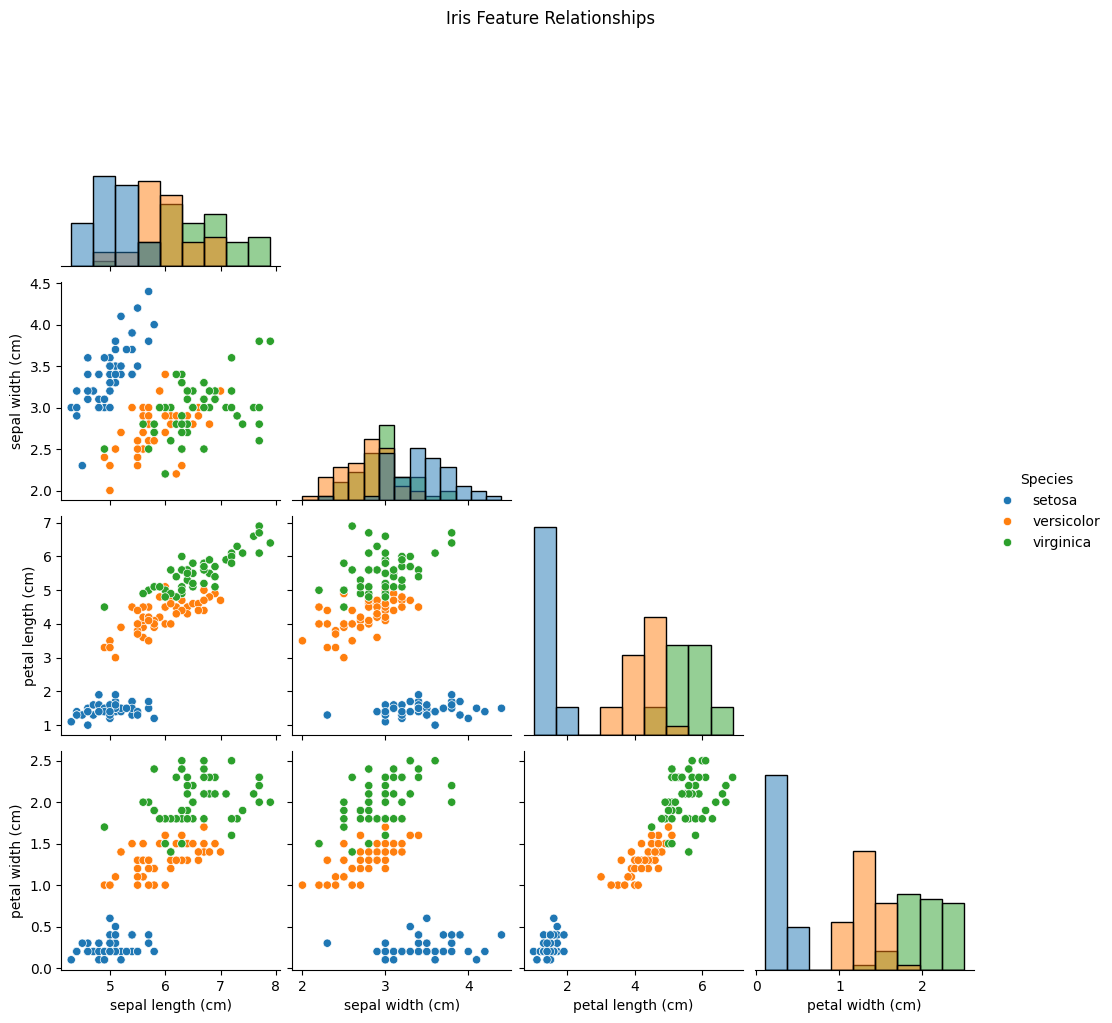

In [ ]:
# Visualize relationships between flower measurements.
sns.pairplot(df, hue="Species", corner=True, diag_kind="hist")
plt.suptitle("Iris Feature Relationships", y=1.02)
plt.show()

## 3. Prepare the data

The data is split into training and testing sets using stratification so that each class keeps approximately the same proportion in both sets.

Feature standardization is important for distance-based algorithms such as KNN because measurements with larger numeric ranges could otherwise dominate the distance calculation. The scaler is fitted on the training data only to avoid data leakage.

In [ ]:
feature_columns = iris.feature_names
X = df[feature_columns].to_numpy(dtype=float)
y = df["Species"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train_scaled))
print("Testing samples:", len(X_test_scaled))
print("Features:", feature_columns)

Training samples: 120
Testing samples: 30
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## 4. Implement distance functions

All three functions return a distance: smaller values indicate more similar samples.

- **Euclidean:** straight-line distance.
- **Manhattan:** sum of absolute coordinate differences.
- **Cosine distance:** one minus cosine similarity.

In [ ]:
def euclidean_distance(x1, x2):
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)
    if x1.shape != x2.shape:
        raise ValueError("Vectors must have the same shape.")
    return float(np.sqrt(np.sum((x1 - x2) ** 2)))


def manhattan_distance(x1, x2):
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)
    if x1.shape != x2.shape:
        raise ValueError("Vectors must have the same shape.")
    return float(np.sum(np.abs(x1 - x2)))


def cosine_distance(x1, x2):
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)
    if x1.shape != x2.shape:
        raise ValueError("Vectors must have the same shape.")

    denominator = np.linalg.norm(x1) * np.linalg.norm(x2)
    if denominator == 0:
        # Define distance for zero vectors explicitly.
        return 0.0 if np.allclose(x1, x2) else 1.0

    similarity = np.dot(x1, x2) / denominator
    similarity = np.clip(similarity, -1.0, 1.0)
    return float(1.0 - similarity)

## 5. Build KNN from scratch

The model stores the training samples. For each test sample, it calculates distances to all training samples, selects the `k` smallest distances, and predicts the majority class among those neighbours.

In [ ]:
class KNN:
    def __init__(self, k=3, distance_metric="euclidean"):
        if not isinstance(k, int) or k < 1:
            raise ValueError("k must be a positive integer.")

        self.k = k
        self.distance_metric = distance_metric
        self.distance_functions = {
            "euclidean": euclidean_distance,
            "manhattan": manhattan_distance,
            "cosine": cosine_distance,
        }

        if distance_metric not in self.distance_functions:
            raise ValueError(
                f"Unsupported metric: {distance_metric}. "
                f"Choose from {list(self.distance_functions)}."
            )

    def fit(self, X_train, y_train):
        X_train = np.asarray(X_train, dtype=float)
        y_train = np.asarray(y_train)

        if len(X_train) != len(y_train):
            raise ValueError("X_train and y_train must have the same number of samples.")
        if self.k > len(X_train):
            raise ValueError("k cannot be greater than the number of training samples.")

        self.X_train = X_train
        self.y_train = y_train
        return self

    def predict(self, X_test):
        X_test = np.asarray(X_test, dtype=float)
        return np.array([self._predict(sample) for sample in X_test])

    def _predict(self, sample):
        distance_function = self.distance_functions[self.distance_metric]
        distances = [
            distance_function(sample, train_sample)
            for train_sample in self.X_train
        ]

        nearest_indices = np.argsort(distances)[:self.k]
        nearest_labels = self.y_train[nearest_indices]

        # Counter.most_common resolves a tie by first encountered label.
        return Counter(nearest_labels).most_common(1)[0][0]

## 6. Train and compare distance metrics

The same value of `k` and the same train/test split are used for each distance metric so the comparison is consistent.

In [ ]:
results = []
predictions_by_metric = {}

for metric in ["euclidean", "manhattan", "cosine"]:
    model = KNN(k=3, distance_metric=metric)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    predictions_by_metric[metric] = y_pred

    results.append({
        "Distance Metric": metric.title(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Correct Predictions": int(np.sum(y_pred == y_test)),
        "Incorrect Predictions": int(np.sum(y_pred != y_test)),
    })

results_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Distance Metric,Accuracy,Correct Predictions,Incorrect Predictions
0,Manhattan,0.9667,29,1
1,Euclidean,0.9333,28,2
2,Cosine,0.8333,25,5


## 7. Detailed evaluation

The classification report provides precision, recall, and F1-score for each Iris class. A confusion matrix shows which classes were correctly or incorrectly predicted.

\nClassification report — Euclidean
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



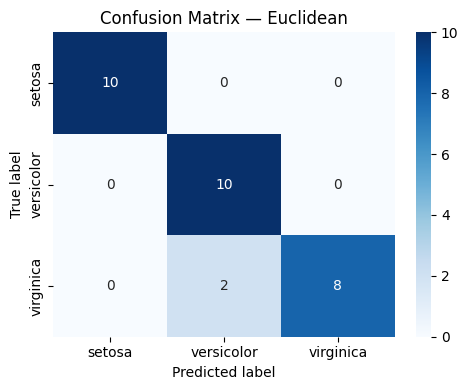

\nClassification report — Manhattan
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



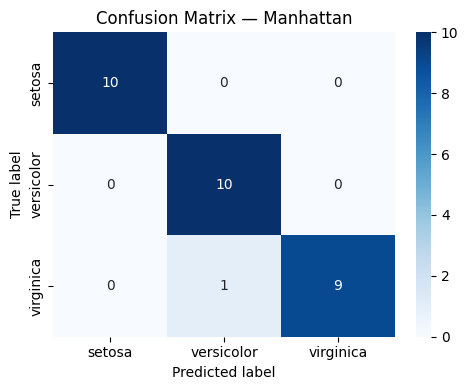

\nClassification report — Cosine
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.86      0.60      0.71        10
   virginica       0.69      0.90      0.78        10

    accuracy                           0.83        30
   macro avg       0.85      0.83      0.83        30
weighted avg       0.85      0.83      0.83        30



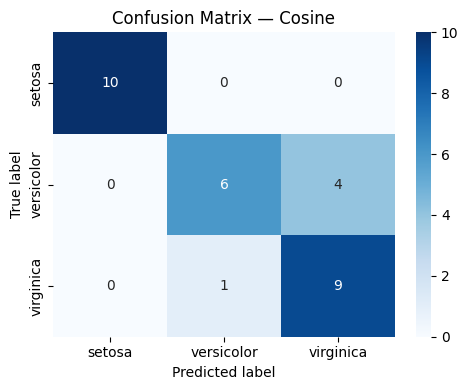

In [ ]:
for metric, y_pred in predictions_by_metric.items():
    print(f"\\nClassification report — {metric.title()}")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names
    )
    plt.title(f"Confusion Matrix — {metric.title()}")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

## 8. Visualize accuracy comparison

The chart compares test accuracy for the three distance metrics. Results can vary if the split, preprocessing, or value of `k` changes.

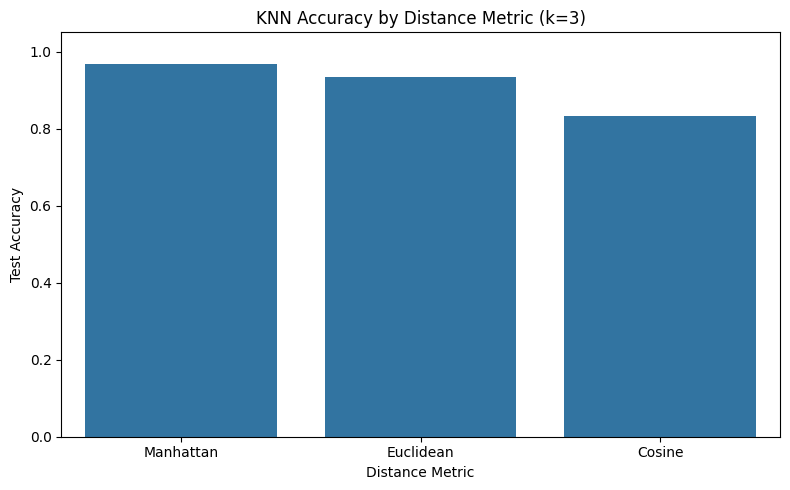

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Distance Metric", y="Accuracy")
plt.ylim(0, 1.05)
plt.title("KNN Accuracy by Distance Metric (k=3)")
plt.ylabel("Test Accuracy")
plt.xlabel("Distance Metric")
plt.tight_layout()
plt.show()

## Conclusion

This project demonstrates how KNN classification works from scratch and how the selected distance metric affects its predictions. Standardizing the measurements ensures that each feature contributes on a comparable scale. Accuracy, precision, recall, F1-score, and confusion matrices provide complementary views of model performance.

**Limitations:** this experiment uses one train/test split and a fixed value of `k=3`. Further work could evaluate multiple `k` values, use cross-validation, and compare additional distance metrics.